# Limpieza y análisis de la Base de Datos de Inclusión Financiera (CNBV, marzo 2026)

**Autor:** Leonardo Chapa Gallardo · Estudiante de Actuaría, Facultad de Ciencias, UNAM

**Objetivo:** convertir dos hojas municipales del Excel público de la CNBV en una tabla limpia y validada, y usarla para medir el acceso a infraestructura financiera en México.

**Fuente:** [CNBV, Bases de Datos de Inclusión Financiera](https://www.gob.mx/cnbv/acciones-y-programas/bases-de-datos-de-inclusion-financiera), corte a marzo de 2026. Datos públicos.

In [1]:
import sys
sys.path.insert(0, "src")
import pandas as pd
pd.set_option("display.max_columns", 12, "display.width", 140)

from limpieza import limpiar_hoja, unir, leer_hoja
from analisis import marcar, tasas, nacional, estilo, grafica_estados, grafica_rezago, grafica_sectores, grafica_sin_acceso, SUC, CAJ, COR

RUTA = "datos_crudos/BDIF_202603.xlsx"


## 1. Cómo viene el archivo original

El Excel tiene 19 hojas pensadas para leerse a mano, no para analizarse. En las hojas municipales:

- Hay 8 filas de portada antes de los datos; la fila 2 trae sumas de control por columna.
- El encabezado ocupa **4 filas con celdas combinadas** (tema → sector → grupo → variable).
- Los nombres de variable traen saltos de línea y la unidad pegada, por ejemplo `"Sucursales\nNúmero"`.
- La columna A está vacía.
- Al final hay un registro artificial `99999 · No identificado` con población cero.

In [2]:
crudo = pd.read_excel(RUTA, sheet_name="BD Infraestructura Mun", header=None)
print("Tamaño de la hoja tal cual:", crudo.shape)
crudo.iloc[8:15, 1:8]

Tamaño de la hoja tal cual: (2491, 48)


,1,2,3,4,5,6,7
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Información general,NaN,NaN,NaN,NaN,NaN,NaN
10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,Clave Municipio,Clave \nEstado,Región,Estado,Municipio,Población total,Población adulta
12,1001,1,Occidente y Bajío,Aguascalientes,Aguascalientes,1041029,798255
13,1002,1,Occidente y Bajío,Aguascalientes,Asientos,58734,41526
14,1003,1,Occidente y Bajío,Aguascalientes,Calvillo,61159,45167


## 2. Limpieza

Todo el proceso está en `src/limpieza.py`. Para cada hoja:

1. **Aplana el encabezado de 4 niveles:** rellena hacia la derecha las celdas combinadas y une los niveles en un nombre `sector__grupo__variable` en *snake_case* sin acentos (por ejemplo, `bm__infraestructura__cajeros_automaticos`).
2. **Quita** la columna vacía, la portada y las filas vacías.
3. **Tipa** las claves y los conteos como enteros (se detiene si aparece un decimal) y normaliza los espacios en el texto.
4. **Valida** contra el propio archivo, y si algo no cuadra se detiene en vez de seguir en silencio.

In [3]:
infra, bitacora_infra = limpiar_hoja(RUTA, "BD Infraestructura Mun")
capt, bitacora_capt = limpiar_hoja(RUTA, "BD Captación Mun")

for nombre, bitacora in [("Infraestructura", bitacora_infra), ("Captación", bitacora_capt)]:
    print(f"\n{nombre}")
    for linea in bitacora:
        print("  ✓", linea)


Infraestructura
  ✓ 2,479 registros, clave de municipio única
  ✓ La clave de estado coincide con los primeros dígitos de la clave municipal
  ✓ Población adulta = mujeres + hombres en todos los municipios
  ✓ Sin valores negativos; 0 celdas vacías
  ✓ 36 columnas cuadran exactamente con la fila de totales del archivo
  ✓ 7 columnas agregadas = suma exacta de sus sectores, municipio por municipio
  ✓ Registro 99999 'No identificado' con población 0: se conserva en totales y se excluye de indicadores por habitante

Captación
  ✓ 2,479 registros, clave de municipio única
  ✓ La clave de estado coincide con los primeros dígitos de la clave municipal
  ✓ Población adulta = mujeres + hombres en todos los municipios
  ✓ Sin valores negativos; 0 celdas vacías
  ✓ 38 columnas cuadran exactamente con la fila de totales del archivo
  ✓ 12 columnas agregadas = suma exacta de sus sectores, municipio por municipio
  ✓ Registro 99999 'No identificado' con población 0: se conserva en totales y se ex

## 3. Unión de las dos hojas y banderas de calidad

Las dos hojas se unen por clave municipal, después de comprobar que traen los mismos municipios con la misma información general. Las columnas de captación llevan el prefijo `capt__`.

Al revisar la población aparecieron **4 registros sin población**, que romperían cualquier tasa por habitante (división entre cero):

- `99999 No identificado`: puntos de acceso que la CNBV no pudo ubicar en un municipio.
- **Villa de Pozos** (SLP), **Eldorado** y **Juan José Ríos** (Sinaloa): municipios de creación reciente que todavía no tienen dato de población, aunque sí reportan sucursales, cajeros y cuentas.

No se borran, porque sus sucursales y cuentas existen y cuentan en los totales. Se marcan con banderas y se excluyen solo de los indicadores por habitante.

In [4]:
bdif = marcar(unir(infra, capt))
print("Tabla final:", bdif.shape)
bdif.loc[~bdif["usar_en_tasas"], ["clave_mun", "estado", "municipio", "poblacion_adulta", SUC, CAJ, "capt__total__cuentas_total"]]

Tabla final: (2479, 93)


,clave_mun,estado,municipio,poblacion_adulta,total__infraestructura__sucursales,total__infraestructura__cajeros_automaticos,capt__total__cuentas_total
1889,24059,San Luis Potosí,Villa de Pozos,0,1,16,20123
1908,25019,Sinaloa,Eldorado,0,0,1,7082
1909,25020,Sinaloa,Juan José Ríos,0,0,1,8093
2478,99999,No identificado,No identificado,0,7,3,31204


## 4. Indicadores

Las tasas de un grupo (estado, tipo de población, etc.) se calculan **sumando numeradores y denominadores antes de dividir**. No se promedian las tasas municipales, porque así un municipio de 500 adultos pesaría lo mismo que uno de un millón.

In [5]:
nac = nacional(bdif)
por_estado = tasas(bdif, "estado")
por_rezago = tasas(bdif, "indice_de_rezago_social")
por_tipo = tasas(bdif, "tipo_de_poblacion")
print("Nacional (por cada 10,000 adultos):")
print(nac.to_string())
por_tipo[["municipios", "municipios_sin_acceso", "pct_municipios_sin_acceso", "sucursales_por_10k", "cajeros_por_10k", "corresponsales_por_10k"]]

Nacional (por cada 10,000 adultos):
sucursales_por_10k        1.71
cajeros_por_10k           6.78
corresponsales_por_10k    6.34


,municipios,municipios_sin_acceso,pct_municipios_sin_acceso,sucursales_por_10k,cajeros_por_10k,corresponsales_por_10k
tipo_de_poblacion,,,,,,
En transición,629,15,2.4,2.08,3.34,4.47
Metrópoli,19,0,0.0,1.65,8.31,7.07
Rural,649,265,40.8,2.68,3.24,3.8
Semi-metrópoli,74,0,0.0,1.65,8.74,7.17
Semi-urbano,728,1,0.1,1.78,3.65,4.75
Urbano,376,0,0.0,1.69,5.86,6.13


In [6]:
por_rezago.loc[["Muy bajo", "Bajo", "Medio", "Alto", "Muy alto"], ["municipios", "pct_municipios_sin_acceso", "sucursales_por_10k", "cajeros_por_10k", "corresponsales_por_10k"]]

,municipios,pct_municipios_sin_acceso,sucursales_por_10k,cajeros_por_10k,corresponsales_por_10k
indice_de_rezago_social,,,,,
Muy bajo,677,1.5,1.73,8.01,7.05
Bajo,893,8.6,1.79,4.37,5.35
Medio,504,18.5,1.54,2.57,3.57
Alto,243,27.6,1.29,1.88,2.5
Muy alto,152,21.1,1.31,1.53,1.29


In [7]:
sin_acceso = bdif[bdif["usar_en_tasas"] & bdif["sin_punto_de_acceso"]]
print(f"Municipios sin ningún punto de acceso: {len(sin_acceso)}  ·  adultos que viven ahí: {int(sin_acceso['poblacion_adulta'].sum()):,}")
sin_acceso.groupby("estado").agg(municipios=("clave_mun", "size"), adultos=("poblacion_adulta", "sum")).sort_values("municipios", ascending=False).head(5)

Municipios sin ningún punto de acceso: 281  ·  adultos que viven ahí: 418,374


,municipios,adultos
estado,,
Oaxaca,235,296552
Puebla,16,59083
Yucatán,8,17343
Veracruz,6,10889
Sonora,4,2108


## 5. Gráficas

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


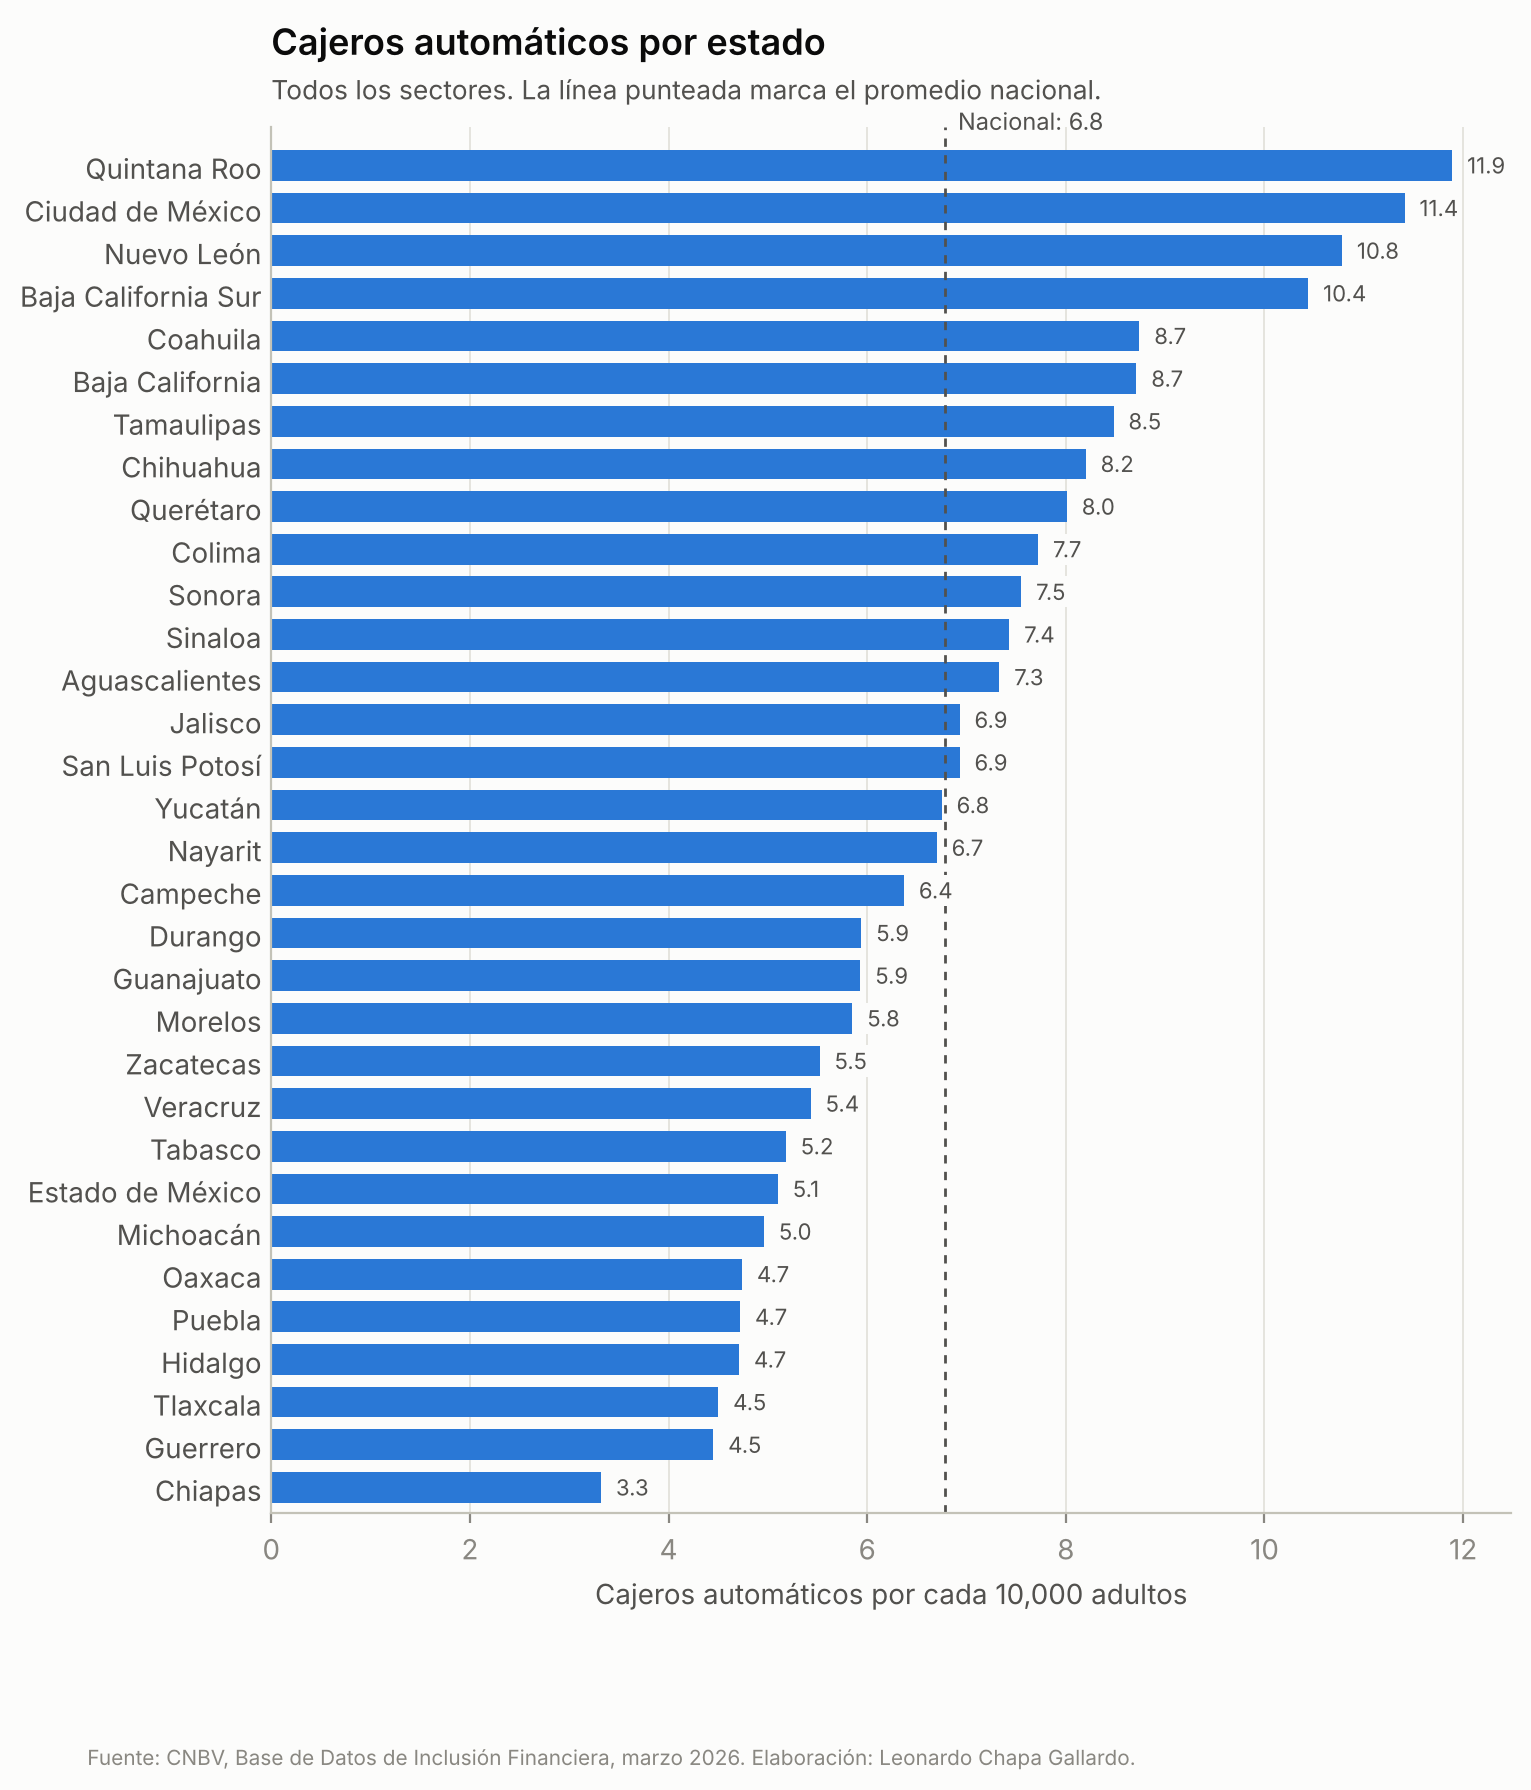

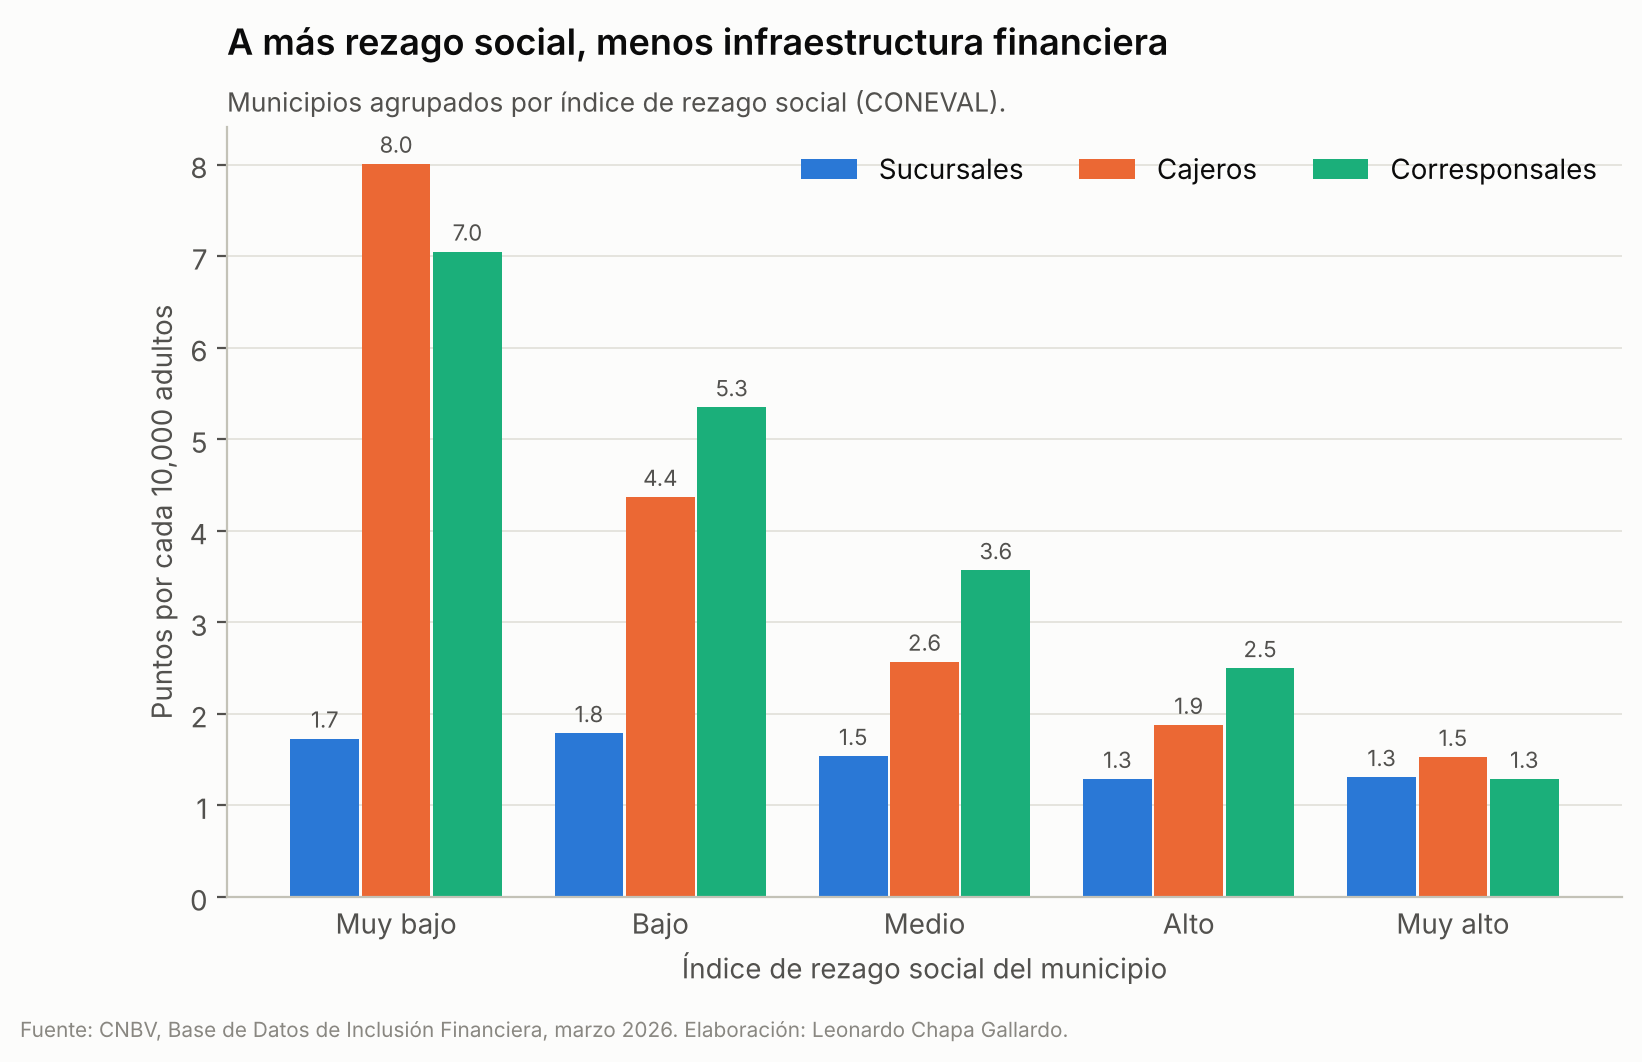

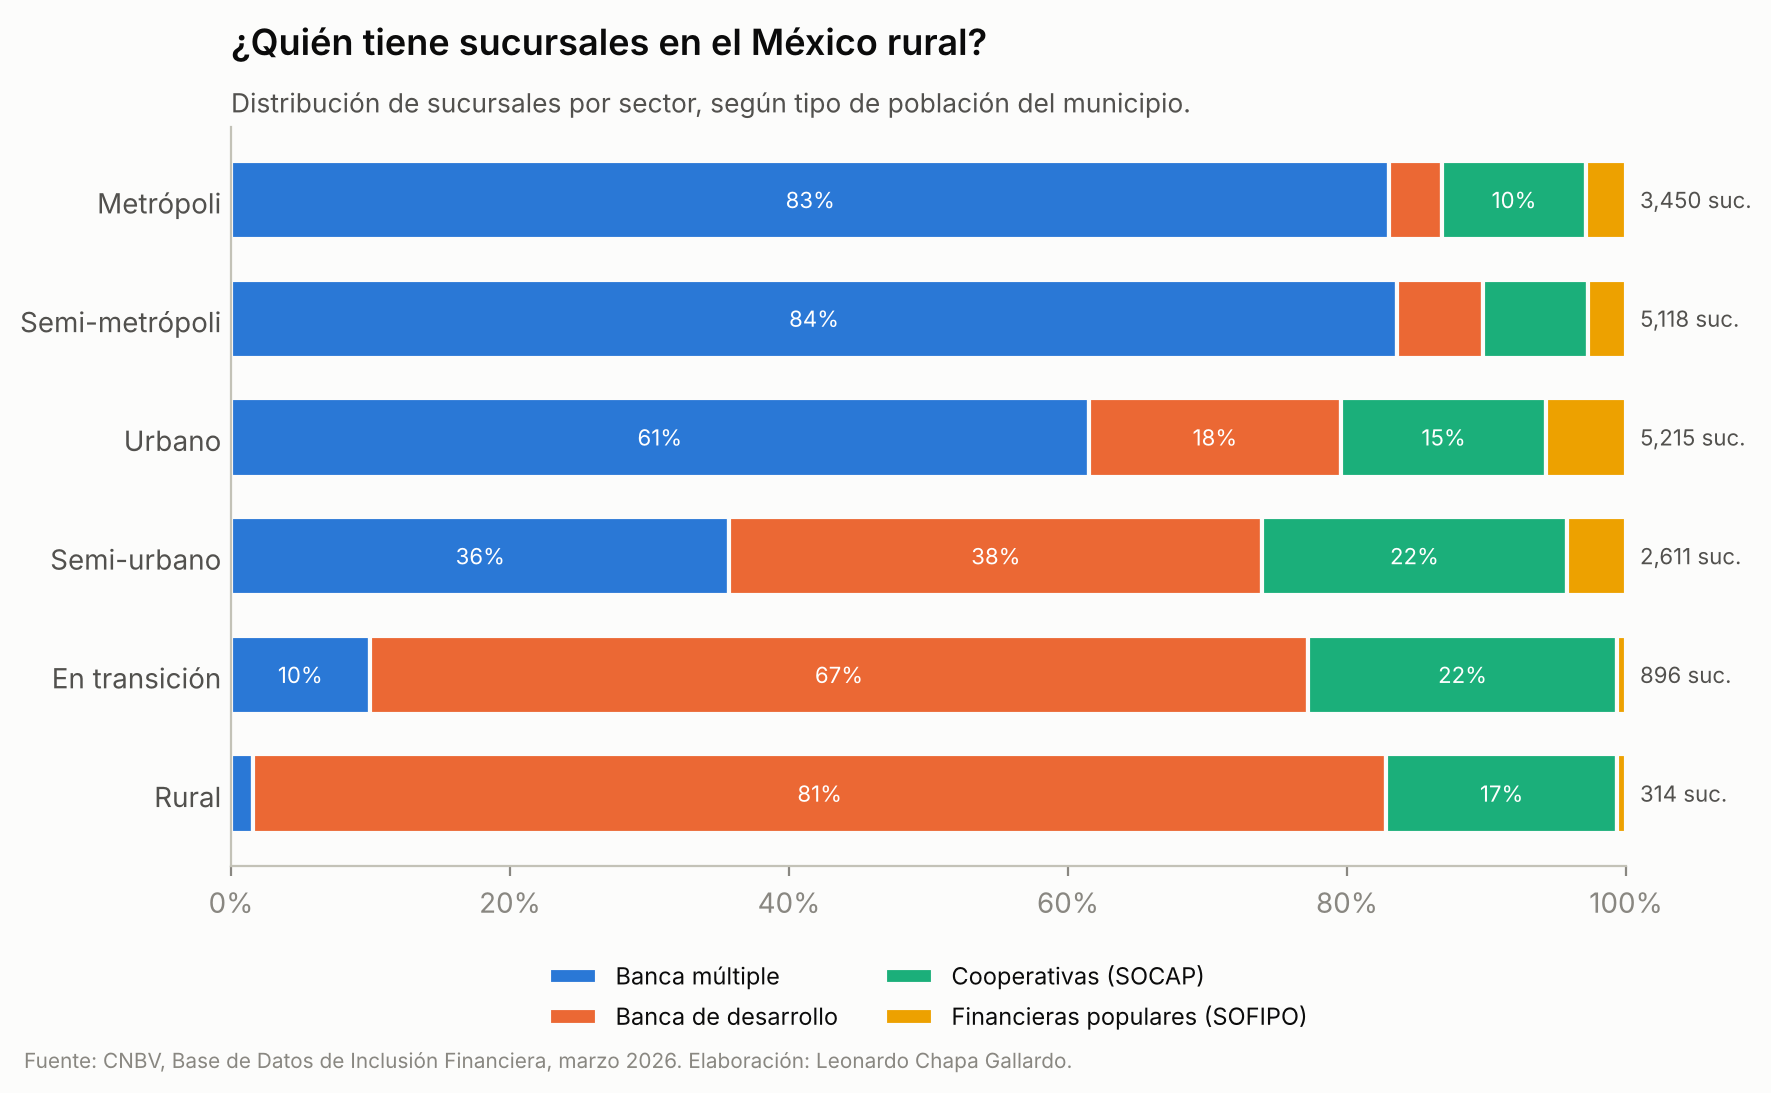

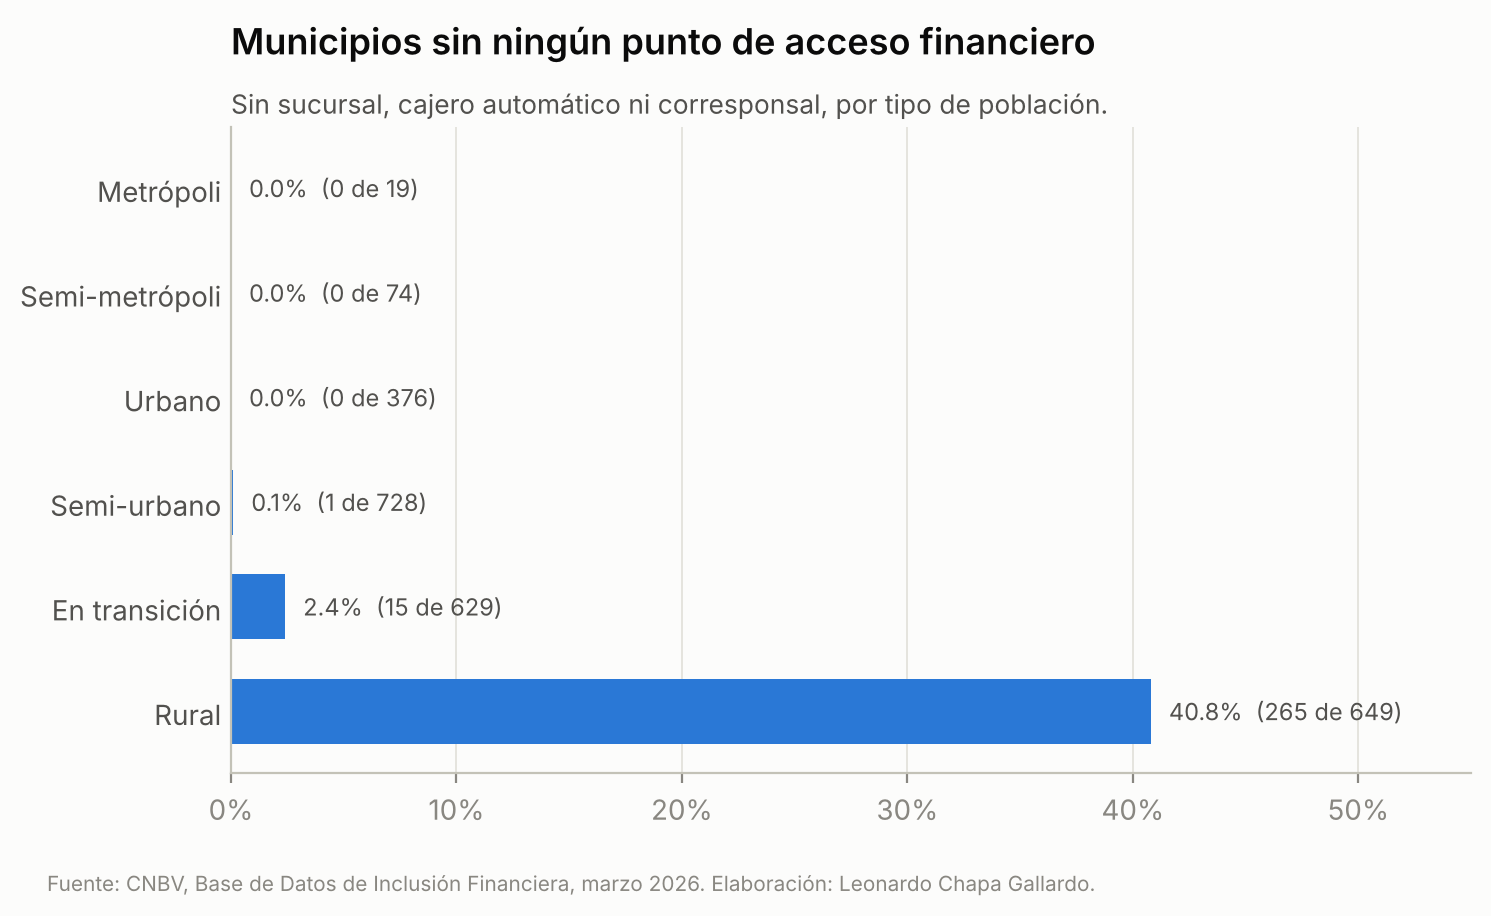

In [8]:
from IPython.display import Image, display
import os
os.makedirs("graficas", exist_ok=True)
estilo()
grafica_estados(por_estado, nac["cajeros_por_10k"], "graficas/1_cajeros_por_estado.png")
grafica_rezago(por_rezago, "graficas/2_rezago_social.png")
grafica_sectores(bdif, "graficas/3_sucursales_por_sector.png")
grafica_sin_acceso(por_tipo, "graficas/4_municipios_sin_acceso.png")
for g in sorted(os.listdir("graficas")):
    display(Image(f"graficas/{g}", width=720))

## 6. Hallazgos

Ver `README.md` para el resumen con cifras. Una advertencia de interpretación: los indicadores de **captación** (cuentas por adulto) se asignan al municipio donde se registra la cuenta, que no siempre es donde vive la persona. Por eso la Ciudad de México sale muy por encima del resto (las sedes bancarias concentran registros). Para comparar estados conviene usar la infraestructura (sucursales, cajeros, corresponsales), que sí está ubicada físicamente.

## 7. Exportación

In [9]:
from exportar import exportar
exportar(bdif, por_estado, por_rezago, por_tipo, bitacora_infra, bitacora_capt, "salida/BDIF_202603_limpia.xlsx")
bdif.to_csv("salida/BDIF_202603_municipal_limpia.csv", index=False, encoding="utf-8-sig")
print("Listo:", sorted(os.listdir("salida")))

Listo: ['BDIF_202603_limpia.xlsx', 'BDIF_202603_municipal_limpia.csv']
